In [ ]:
%pip install duckdb

In [ ]:
import duckdb

conn = duckdb.connect('dados_originais')

# Insere os dados do CSV na tabela 'sales' existente
conn.execute("INSERT INTO sales SELECT * FROM read_csv_auto('seu_arquivo.csv')")

conn.close()

In [16]:
import warnings
warnings.filterwarnings('ignore')

import duckdb
import numpy as np
import pandas as pd
import os
from typing_extensions import TypedDict
from typing import List, Annotated
from IPython.display import Image, display, HTML
import matplotlib.pyplot as plt
import io
import base64

# Importações dos módulos do LangGraph
from langchain_openai.chat_models import ChatOpenAI
from langgraph.graph import StateGraph, END, START
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import SystemMessage, HumanMessage

from operator import add




In [17]:
import os
from getpass import getpass
from langchain_openai import ChatOpenAI

api_key = getpass("Cole sua OpenAI API Key: ").strip()

os.environ["OPENAI_API_KEY"] = api_key



In [18]:


model = ChatOpenAI(model_name="gpt-4o", temperature=0.7)


In [19]:
# Definir o estado do agente usando TypedDict
class AgentState(TypedDict):
    question: str
    table_schemas: str
    database: str
    sql: str
    reflect: Annotated[List[str], add]
    accepted: bool
    revision: int
    max_revision: int
    results: List[tuple]
    interpretation: str
    plot_needed: bool
    plot_html: str


In [20]:
# Função para obter o esquema do banco de dados


def get_database_schema(db_path):
    conn = duckdb.connect(db_path)
    cursor = conn.cursor()
    cursor.execute("SELECT table_name FROM information_schema.tables WHERE table_schema='main'")
    tables = cursor.fetchall()
    schema = ''
    for table_name in tables:
        table_name = table_name[0]
        cursor.execute(f"DESCRIBE {table_name}")
        columns = cursor.fetchall()
        schema += f"Tabela: {table_name}\n"
        schema += "Colunas:\n"
        for column in columns:
            schema += f" - {column[0]} ({column[1]})\n"
        schema += '\n'
    conn.close()
    return schema

# Definir os nós para o LangGraph
def search_engineer_node(state: AgentState):
    db_schema = get_database_schema('dados_originais')
    state['table_schemas'] = db_schema
    state['database'] = 'dados_originais'
    return state

def sql_writer_node(state: AgentState):
    role_prompt = """
Você é um especialista em DuckDB e sua sintaxe SQL. Sua tarefa é escrever **apenas** a consulta SQL que responda à pergunta do usuário. A consulta deve:

- Crie databases no DuckDB.
- Usar a sintaxe SQL do DuckDB padrão em inglês.
- Utilizar os nomes das tabelas e colunas conforme definidos no esquema do banco de dados.
- Não incluir comentários, explicações ou qualquer texto adicional.
- Não utilizar formatação de código ou markdown.
- Retornar apenas a consulta SQL válida.
"""
    instruction = f"Esquema do banco de dados:\n{state['table_schemas']}\n"
    if len(state['reflect']) > 0:
        instruction += f"Considere os seguintes feedbacks:\n{chr(10).join(state['reflect'])}\n"
    instruction += f"Escreva a consulta SQL que responda à seguinte pergunta: {state['question']}\n"
    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]
    response = model.invoke(messages)
    state['sql'] = response.content.strip()
    state['revision'] += 1
    return state

def qa_engineer_node(state: AgentState):
    role_prompt = """
Você é um engenheiro de QA especializado no banco relacional DuckDB e sua sintaxe SQL. Sua tarefa é verificar se a consulta SQL fornecida responde corretamente à pergunta do usuário.
"""
    instruction = f"Com base no seguinte esquema de banco de dados:\n{state['table_schemas']}\n"
    instruction += f"E na seguinte consulta SQL:\n{state['sql']}\n"
    instruction += f"Verifique se a consulta SQL pode completar a tarefa: {state['question']}\n"
    instruction += "Responda 'ACEITO' se estiver correta ou 'REJEITADO' se não estiver.\n"
    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]
    response = model.invoke(messages)
    state['accepted'] = 'ACEITO' in response.content.upper()
    return state

def chief_dba_node(state: AgentState):
    role_prompt = """
Você é um DBA experiente, especialista em DuckDB. Sua tarefa é fornecer feedback detalhado para melhorar a consulta SQL fornecida.
"""
    instruction = f"Com base no seguinte esquema de banco de dados:\n{state['table_schemas']}\n"
    instruction += f"E na seguinte consulta SQL:\n{state['sql']}\n"
    instruction += f"Por favor, forneça recomendações úteis e detalhadas para ajudar a melhorar a consulta SQL para a tarefa: {state['question']}\n"
    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]
    response = model.invoke(messages)
    state['reflect'].append(response.content)
    return state

def execute_query_node(state: AgentState):
    conn = duckdb.connect(state['database'])
    cursor = conn.cursor()
    try:
        cursor.execute(state['sql'])
        state['results'] = cursor.fetchall()
    except Exception as e:
        state['results'] = []
        state['error'] = str(e)
    finally:
        cursor.close()
        conn.close()
    return state

def interpret_results_node(state: AgentState):
    role_prompt = """
Você é um assistente especializado em interpretar resultados de consultas SQL comn a sintaxe do DuckDB, explicá-los em linguagem natural e sugerir visualizações apropriadas. Evite sugerir gráficos quando o resultado for um único valor.
Sua tarefa é analisar os resultados da consulta, fornecer uma resposta clara e concisa à pergunta original do usuário e sugerir um tipo de gráfico adequado se houver dados numéricos para comparar com outras unidades, locais, clientes, etc.
"""
    instruction = f"Pergunta original: {state['question']}\n"
    instruction += f"Consulta SQL executada: {state['sql']}\n"
    instruction += f"Resultados da consulta: {state['results']}\n"
    instruction += "Por favor, interprete esses resultados, responda à pergunta original em linguagem natural e sugira um tipo de gráfico adequado se aplicável, especialmente quando houver dados numéricos e comparações.Se a resposta for tipo O maior ou o mais caro, indicando unidade máxima, evite plotar gráficos"
    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]
    response = model.invoke(messages)
    state['interpretation'] = response.content
    # Decidir se um gráfico é necessário com base na interpretação
    if "gráfico" in response.content.lower() or "gráfico" in response.content.lower():
        state['plot_needed'] = True
    else:
        state['plot_needed'] = False
    return state


In [21]:
def plot_results_node(state: AgentState):
    if not state['plot_needed']:
        state['plot_html'] = ''
        return state
    # Gerar o gráfico
    results = state['results']
    if not results or len(results) == 0:
        state['plot_html'] = ''
        return state
    # Assumindo que a primeira coluna são rótulos e a última coluna são valores
    labels = [str(row[0]) for row in results]
    values = [row[-1] if isinstance(row[-1], (int, float)) else 0 for row in results]
    plt.figure(figsize=(10, 6))
    # Determinar o tipo de gráfico com base na sugestão
    if "barra" in state['interpretation'].lower():
        plt.bar(labels, values)
    elif "pizza" in state['interpretation'].lower():
        plt.pie(values, labels=labels, autopct='%1.1f%%')
    else:  # padrão para gráfico de linhas
        plt.plot(labels, values, marker='o')
    plt.title(state['question'])
    plt.xlabel('Categorias')
    plt.ylabel('Valores')
    plt.xticks(rotation=45)
    plt.tight_layout()
    # Salvar o gráfico em um buffer
    buf = io.BytesIO()
    plt.savefig(buf, format='png')
    buf.seek(0)
    plt.close()
    # Converter o gráfico para base64
    img_base64 = base64.b64encode(buf.getvalue()).decode('utf-8')
    # Criar HTML para exibir o gráfico
    img_html = f'<img src="data:image/png;base64,{img_base64}">'
    state['plot_html'] = img_html
    return state

In [22]:
# Construir o LangGraph
builder = StateGraph(AgentState)

# Adicionar nós ao grafo
builder.add_node('search_engineer', search_engineer_node)
builder.add_node('sql_writer', sql_writer_node)
builder.add_node('qa_engineer', qa_engineer_node)
builder.add_node('chief_dba', chief_dba_node)
builder.add_node('execute_query', execute_query_node)
builder.add_node('interpret_results', interpret_results_node)
builder.add_node('plot_results', plot_results_node)

# Definir as arestas entre os nós
builder.add_edge(START, 'search_engineer')
builder.add_edge('search_engineer', 'sql_writer')
builder.add_edge('sql_writer', 'qa_engineer')

# Aresta condicional do qa_engineer
builder.add_conditional_edges(
    'qa_engineer',
    lambda state: 'execute_query' if state['accepted'] or state['revision'] >= state['max_revision'] else 'chief_dba',
    {'execute_query': 'execute_query', 'chief_dba': 'chief_dba'}
)

builder.add_edge('chief_dba', 'sql_writer')
builder.add_edge('execute_query', 'interpret_results')
builder.add_edge('interpret_results', 'plot_results')
builder.add_edge('plot_results', END)

# Definir o ponto de entrada
builder.set_entry_point('search_engineer')

# Compilar o grafo com um checkpointer
memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

In [23]:
# Função para processar uma pergunta usando o grafo
def process_question(question):
    initial_state = {
        'question': question,
        'table_schemas': '',
        'database': '',
        'sql': '',
        'reflect': [],
        'accepted': False,
        'revision': 0,
        'max_revision': 2,
        'results': [],
        'interpretation': '',
        'plot_needed': False,
        'plot_html': ''
    }
    thread = {'configurable': {'thread_id': '1'}}
    for s in graph.stream(initial_state, thread):
        pass
    # Obter o estado final
    final_state = graph.get_state(thread).values

    # Imprimir os resultados
    print('Consulta SQL Gerada:\n', final_state['sql'])
    print('\nResultados da Consulta:')
    if 'results' in final_state:
        for result in final_state['results']:
            print(result)
    else:
        print('Nenhum resultado')
    print('\nInterpretação:')
    print(final_state['interpretation'])
    if final_state.get('plot_html'):
        display(HTML(final_state['plot_html']))
    else:
        print('Nenhum gráfico gerado.')

Consulta SQL Gerada:
 SELECT COUNT(DISTINCT CustomerId) FROM churn

Resultados da Consulta:
[10000]

Interpretação:
A consulta SQL foi projetada para contar o número total de clientes distintos na tabela "churn". O resultado da consulta é que existem 10.000 clientes únicos.

Como a pergunta é sobre uma contagem total única, não é necessário sugerir um gráfico neste caso. A resposta é um único valor e não envolve comparações ou distribuições que se beneficiariam de uma visualização gráfica.



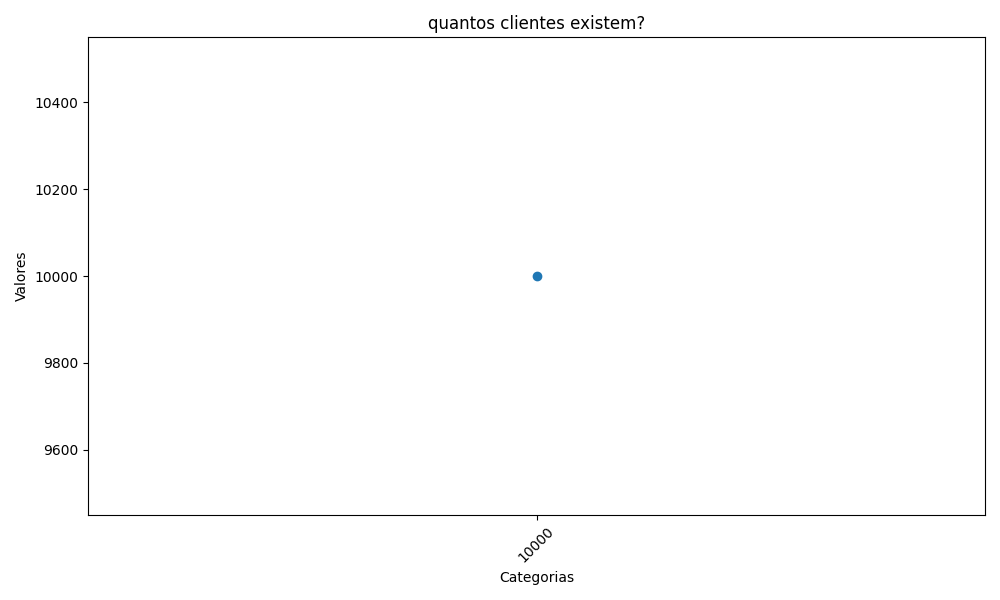

In [24]:
pergunta = "quantos clientes existem?"
process_question(pergunta)

Consulta SQL Gerada:
 SELECT Gender, COUNT(*) AS Count FROM churn GROUP BY Gender

Resultados da Consulta:
['Male', 5457]
['Female', 4543]

Interpretação:
Os resultados da consulta indicam que há 5.457 clientes do gênero masculino e 4.543 clientes do gênero feminino. Isso significa que a base de clientes é composta por aproximadamente 54,5% de homens e 45,5% de mulheres.

Para visualizar essa distribuição de forma clara, um gráfico de pizza seria apropriado. Esse tipo de gráfico ajudará a destacar a proporção entre clientes masculinos e femininos, permitindo uma fácil comparação visual entre os dois grupos.



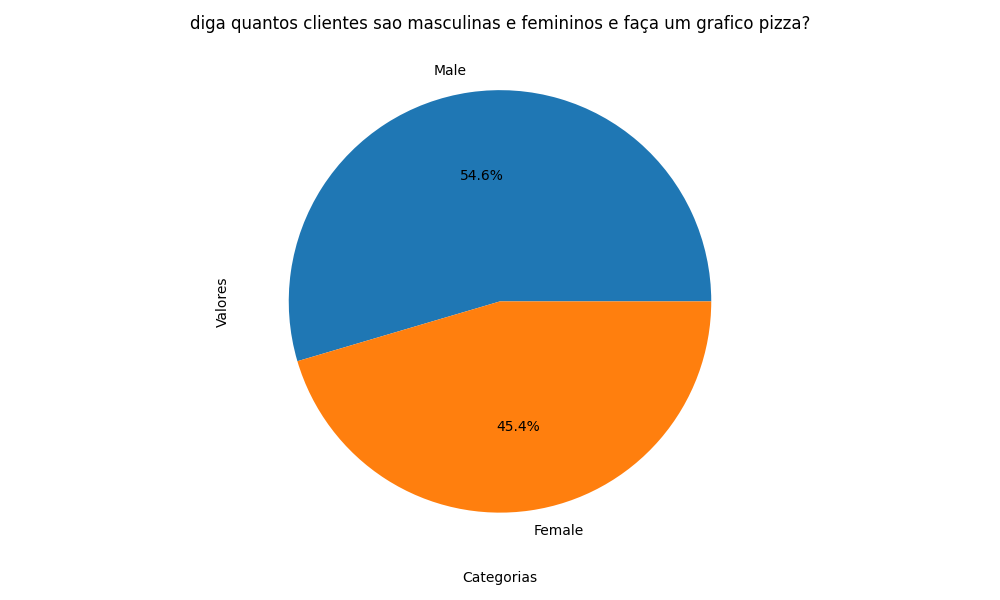

In [35]:
pergunta = "diga quantos clientes sao masculinas e femininos e faça um grafico pizza?"
process_question(pergunta)

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import duckdb
import numpy as np
import pandas as pd
import os
from typing_extensions import TypedDict
from typing import List, Annotated
from IPython.display import Image, display, HTML
import matplotlib.pyplot as plt
import io
import base64

# Importações dos módulos do LangGraph
from langchain_openai.chat_models import ChatOpenAI
from langgraph.graph import StateGraph, END, START
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import SystemMessage, HumanMessage

from operator import add

# Configurar a chave de API da OpenAI (substitua 'sua-chave-api-openai' pela sua chave real)
os.environ['OPENAI_API_KEY'] = 'sk-proj...'

# Definir o modelo de linguagem
model = ChatOpenAI(model_name="gpt-4o", temperature=0)

# Definir o estado do agente usando TypedDict
class AgentState(TypedDict):
    question: str
    table_schemas: str
    database: str
    sql: str
    reflect: Annotated[List[str], add]
    accepted: bool
    revision: int
    max_revision: int
    results: List[tuple]
    interpretation: str
    plot_needed: bool
    plot_html: str

# Função para obter o esquema do banco de dados
def get_database_schema(db_path):
    conn = duckdb.connect(db_path)
    cursor = conn.cursor()
    cursor.execute("SELECT table_name FROM information_schema.tables WHERE table_schema='main'")
    tables = cursor.fetchall()
    schema = ''
    for table_name in tables:
        table_name = table_name[0]
        cursor.execute(f"DESCRIBE {table_name}")
        columns = cursor.fetchall()
        schema += f"Tabela: {table_name}\n"
        schema += "Colunas:\n"
        for column in columns:
            schema += f" - {column[0]} ({column[1]})\n"
        schema += '\n'
    conn.close()
    return schema

# Definir os nós para o LangGraph
def search_engineer_node(state: AgentState):
    db_schema = get_database_schema('dados_originais')
    state['table_schemas'] = db_schema
    state['database'] = 'dados_originais'
    return state

def sql_writer_node(state: AgentState):
    role_prompt = """
Você é um especialista em DuckDB e sua sintaxe SQL. Sua tarefa é escrever **apenas** a consulta SQL que responda à pergunta do usuário. A consulta deve:
- Crie databases no DuckDB.
- Usar a sintaxe SQL do DuckDB padrão em inglês.
- Utilizar os nomes das tabelas e colunas conforme definidos no esquema do banco de dados.
- Não incluir comentários, explicações ou qualquer texto adicional.
- Não utilizar formatação de código ou markdown.
- Retornar apenas a consulta SQL válida.
"""
    instruction = f"Esquema do banco de dados:\n{state['table_schemas']}\n"
    if len(state['reflect']) > 0:
        instruction += f"Considere os seguintes feedbacks:\n{chr(10).join(state['reflect'])}\n"
    instruction += f"Escreva a consulta SQL que responda à seguinte pergunta: {state['question']}\n"
    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]
    response = model.invoke(messages)
    state['sql'] = response.content.strip()
    state['revision'] += 1
    return state

def qa_engineer_node(state: AgentState):
    role_prompt = """
Você é um engenheiro de QA especializado no banco relacional DuckDB e sua sintaxe SQL. Sua tarefa é verificar se a consulta SQL fornecida responde corretamente à pergunta do usuário.
"""
    instruction = f"Com base no seguinte esquema de banco de dados:\n{state['table_schemas']}\n"
    instruction += f"E na seguinte consulta SQL:\n{state['sql']}\n"
    instruction += f"Verifique se a consulta SQL pode completar a tarefa: {state['question']}\n"
    instruction += "Responda 'ACEITO' se estiver correta ou 'REJEITADO' se não estiver.\n"
    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]
    response = model.invoke(messages)
    state['accepted'] = 'ACEITO' in response.content.upper()
    return state

def chief_dba_node(state: AgentState):
    role_prompt = """
Você é um DBA experiente, especialista em DuckDB. Sua tarefa é fornecer feedback detalhado para melhorar a consulta SQL fornecida.
"""
    instruction = f"Com base no seguinte esquema de banco de dados:\n{state['table_schemas']}\n"
    instruction += f"E na seguinte consulta SQL:\n{state['sql']}\n"
    instruction += f"Por favor, forneça recomendações úteis e detalhadas para ajudar a melhorar a consulta SQL para a tarefa: {state['question']}\n"
    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]
    response = model.invoke(messages)
    state['reflect'].append(response.content)
    return state

def execute_query_node(state: AgentState):
    conn = duckdb.connect(state['database'])
    cursor = conn.cursor()
    try:
        cursor.execute(state['sql'])
        state['results'] = cursor.fetchall()
    except Exception as e:
        state['results'] = []
        state['error'] = str(e)
    finally:
        cursor.close()
        conn.close()
    return state

def interpret_results_node(state: AgentState):
    role_prompt = """
Você é um assistente especializado em interpretar resultados de consultas SQL comn a sintaxe do DuckDB, explicá-los em linguagem natural e sugerir visualizações apropriadas. Evite sugerir gráficos quando o resultado for um único valor.
Sua tarefa é analisar os resultados da consulta, fornecer uma resposta clara e concisa à pergunta original do usuário e sugerir um tipo de gráfico adequado se houver dados numéricos para comparar com outras unidades, locais, clientes, etc.
"""
    instruction = f"Pergunta original: {state['question']}\n"
    instruction += f"Consulta SQL executada: {state['sql']}\n"
    instruction += f"Resultados da consulta: {state['results']}\n"
    instruction += "Por favor, interprete esses resultados, responda à pergunta original em linguagem natural e sugira um tipo de gráfico adequado se aplicável, especialmente quando houver dados numéricos e comparações.Se a resposta for tipo O maior ou o mais caro, indicando unidade máxima, evite plotar gráficos"
    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]
    response = model.invoke(messages)
    state['interpretation'] = response.content
    # Decidir se um gráfico é necessário com base na interpretação
    if "gráfico" in response.content.lower() or "gráfico" in response.content.lower():
        state['plot_needed'] = True
    else:
        state['plot_needed'] = False
    return state

def plot_results_node(state: AgentState):
    if not state['plot_needed']:
        state['plot_html'] = ''
        return state
    # Gerar o gráfico
    results = state['results']
    if not results or len(results) == 0:
        state['plot_html'] = ''
        return state
    # Assumindo que a primeira coluna são rótulos e a última coluna são valores
    labels = [str(row[0]) for row in results]
    values = [row[-1] if isinstance(row[-1], (int, float)) else 0 for row in results]
    plt.figure(figsize=(10, 6))
    # Determinar o tipo de gráfico com base na sugestão
    if "barra" in state['interpretation'].lower():
        plt.bar(labels, values)
    elif "pizza" in state['interpretation'].lower():
        plt.pie(values, labels=labels, autopct='%1.1f%%')
    else:  # padrão para gráfico de linhas
        plt.plot(labels, values, marker='o')
    plt.title(state['question'])
    plt.xlabel('Categorias')
    plt.ylabel('Valores')
    plt.xticks(rotation=45)
    plt.tight_layout()
    # Salvar o gráfico em um buffer
    buf = io.BytesIO()
    plt.savefig(buf, format='png')
    buf.seek(0)
    plt.close()
    # Converter o gráfico para base64
    img_base64 = base64.b64encode(buf.getvalue()).decode('utf-8')
    # Criar HTML para exibir o gráfico
    img_html = f'<img src="data:image/png;base64,{img_base64}">'
    state['plot_html'] = img_html
    return state

# Construir o LangGraph
builder = StateGraph(AgentState)

# Adicionar nós ao grafo
builder.add_node('search_engineer', search_engineer_node)
builder.add_node('sql_writer', sql_writer_node)
builder.add_node('qa_engineer', qa_engineer_node)
builder.add_node('chief_dba', chief_dba_node)
builder.add_node('execute_query', execute_query_node)
builder.add_node('interpret_results', interpret_results_node)
builder.add_node('plot_results', plot_results_node)

# Definir as arestas entre os nós
builder.add_edge(START, 'search_engineer')
builder.add_edge('search_engineer', 'sql_writer')
builder.add_edge('sql_writer', 'qa_engineer')

# Aresta condicional do qa_engineer
builder.add_conditional_edges(
    'qa_engineer',
    lambda state: 'execute_query' if state['accepted'] or state['revision'] >= state['max_revision'] else 'chief_dba',
    {'execute_query': 'execute_query', 'chief_dba': 'chief_dba'}
)

builder.add_edge('chief_dba', 'sql_writer')
builder.add_edge('execute_query', 'interpret_results')
builder.add_edge('interpret_results', 'plot_results')
builder.add_edge('plot_results', END)

# Definir o ponto de entrada
builder.set_entry_point('search_engineer')

# Compilar o grafo com um checkpointer
memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

# Função para processar uma pergunta usando o grafo
def process_question(question):
    initial_state = {
        'question': question,
        'table_schemas': '',
        'database': '',
        'sql': '',
        'reflect': [],
        'accepted': False,
        'revision': 0,
        'max_revision': 2,
        'results': [],
        'interpretation': '',
        'plot_needed': False,
        'plot_html': ''
    }
    thread = {'configurable': {'thread_id': '1'}}
    for s in graph.stream(initial_state, thread):
        pass
    # Obter o estado final
    final_state = graph.get_state(thread).values

    # Imprimir os resultados
    print('Consulta SQL Gerada:\n', final_state['sql'])
    print('\nResultados da Consulta:')
    if 'results' in final_state:
        for result in final_state['results']:
            print(result)
    else:
        print('Nenhum resultado')
    print('\nInterpretação:')
    print(final_state['interpretation'])
    if final_state.get('plot_html'):
        display(HTML(final_state['plot_html']))
    else:
        print('Nenhum gráfico gerado.')

Consulta SQL Gerada:
 SELECT COUNT(*) FROM churn;

Resultados da Consulta:
[10000]

Interpretação:
A consulta SQL executada contou o número total de clientes na tabela "churn". O resultado indica que existem 10.000 clientes. Como este é um único valor agregado, não há necessidade de sugerir um gráfico, pois não há dados adicionais para comparar ou visualizar.



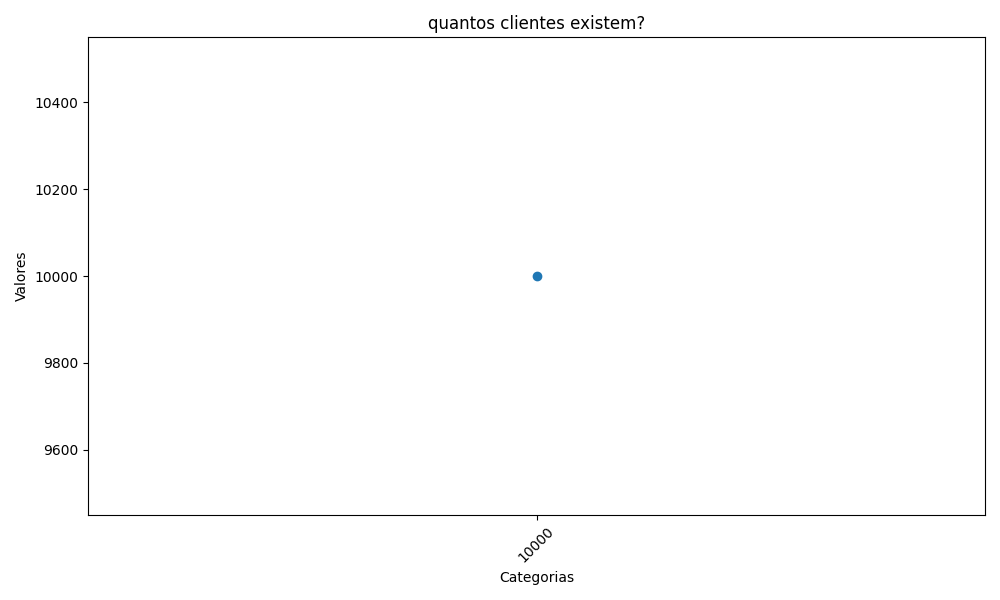

In [2]:
pergunta = "quantos clientes existem?"
process_question(pergunta)

Consulta SQL Gerada:
 SELECT CreditScore FROM churn WHERE Surname = 'Boni';

Resultados da Consulta:
[699]
[726]
[515]
[556]
[602]
[733]
[568]
[780]
[668]
[430]
[606]
[775]
[714]
[634]

Interpretação:
Os resultados da consulta mostram os valores de CreditScore associados ao sobrenome "Boni". Existem 14 registros diferentes, com os seguintes valores de CreditScore: 699, 726, 515, 556, 602, 733, 568, 780, 668, 430, 606, 775, 714 e 634.

Para responder à pergunta original, não há um único valor de CreditScore para "Boni", mas sim uma lista de valores. Isso pode indicar que há várias pessoas com o sobrenome "Boni" na base de dados, cada uma com um CreditScore diferente.

Para visualizar esses dados, um gráfico de barras seria apropriado. Cada barra representaria um dos valores de CreditScore, permitindo uma comparação visual fácil entre os diferentes scores associados ao sobrenome "Boni".



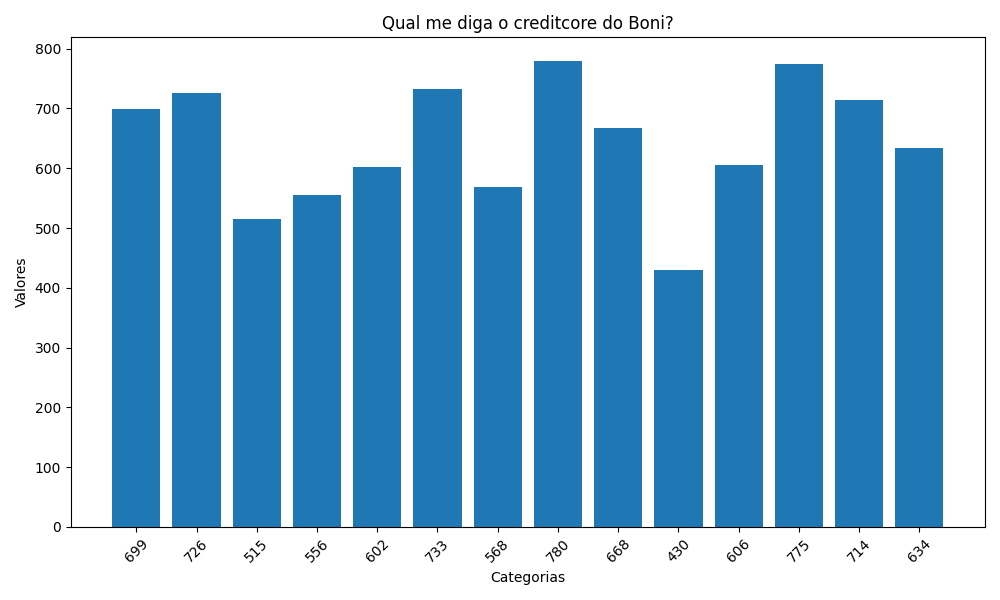

In [3]:
pergunta = "Qual me diga o creditcore do Boni?"
process_question(pergunta)

Consulta SQL Gerada:
 SELECT Geography, COUNT(CustomerId) AS CustomerCount FROM churn GROUP BY Geography

Resultados da Consulta:
['France', 5014]
['Spain', 2477]
['Germany', 2509]

Interpretação:
Os resultados da consulta mostram o número de clientes em cada um dos três países listados: França, Espanha e Alemanha. Especificamente, há 5.014 clientes na França, 2.477 na Espanha e 2.509 na Alemanha.

Para responder à pergunta original, que solicita uma representação gráfica dos clientes por país, um gráfico de pizza seria apropriado. Este tipo de gráfico é ideal para mostrar a proporção de clientes em cada país em relação ao total. Cada fatia do gráfico de pizza representaria a participação de cada país no total de clientes.



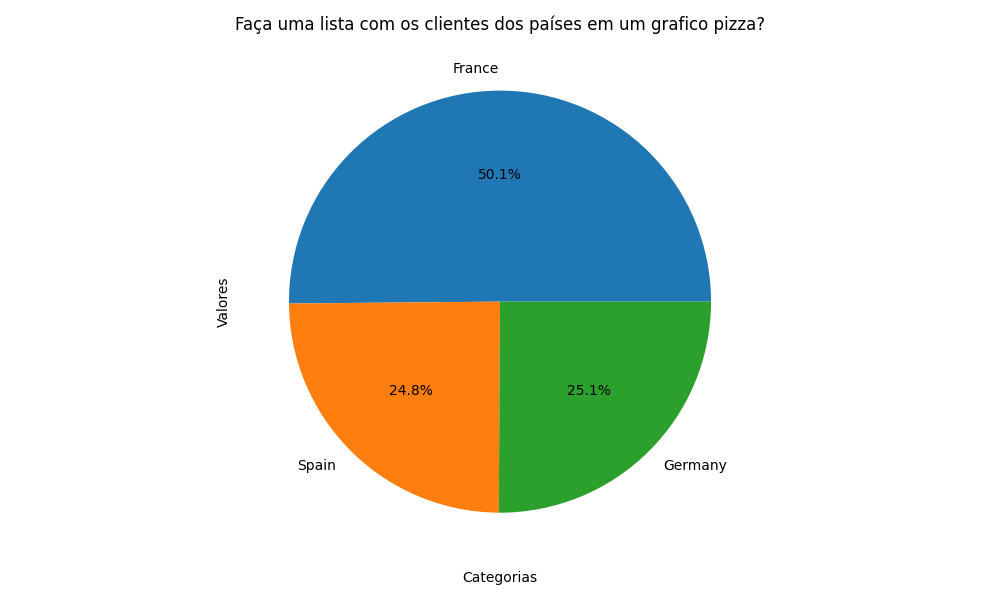

In [10]:
pergunta = "Faça uma lista com os clientes dos países em um grafico pizza?"
process_question(pergunta)

In [39]:
from pathlib import Path

print("Diretório atual:", Path.cwd())
print("Arquivos CSV:", [p.name for p in Path.cwd().glob("*.csv")])


Diretório atual: c:\Users\eugen\Desktop\Kiro
Arquivos CSV: ['Churn_Modelling.csv']


In [14]:
from pathlib import Path
import duckdb

arquivo_csv = Path(
    r"C:\Users\eugen\AppData\Local\Programs\Kiro\banco_de_dados\dados_originais\Churn_Modelling.csv"
)

if not arquivo_csv.is_file():
    raise FileNotFoundError(f"Arquivo não encontrado: {arquivo_csv}")

with duckdb.connect("dados_originais") as conn:
    # Substitui a tabela sales existente.
    conn.execute("""
        CREATE OR REPLACE TABLE sales AS
        SELECT *
        FROM read_csv(?, header = true);
    """, [str(arquivo_csv)])

    total = conn.execute("SELECT COUNT(*) FROM sales").fetchone()[0]

print(f"Banco 'dados_originais': tabela 'sales' criada com {total} registros.")

Banco 'dados_originais': tabela 'sales' criada com 10000 registros.


Consulta SQL Gerada:
 SELECT Geography, Surname FROM churn UNION ALL SELECT Geography, Surname FROM sales ORDER BY Geography, Surname; SELECT Geography, COUNT(CustomerId) AS CustomerCount FROM ( SELECT Geography, CustomerId FROM churn UNION ALL SELECT Geography, CustomerId FROM sales ) AS combined GROUP BY Geography ORDER BY CustomerCount DESC;

Resultados da Consulta:
['France', 10028]
['Germany', 5018]
['Spain', 4954]

Interpretação:
A pergunta original solicitava uma lista com os nomes dos clientes de cada país e um gráfico de pizza com o número de clientes por país. A consulta SQL executada retornou o número de clientes em três países: França, Alemanha e Espanha.

Os resultados mostram que:
- A França tem 10.028 clientes.
- A Alemanha tem 5.018 clientes.
- A Espanha tem 4.954 clientes.

Para responder à pergunta original, podemos afirmar que a lista de clientes foi gerada, mas o foco aqui está nos números de clientes por país. A França possui o maior número de clientes entre os trê


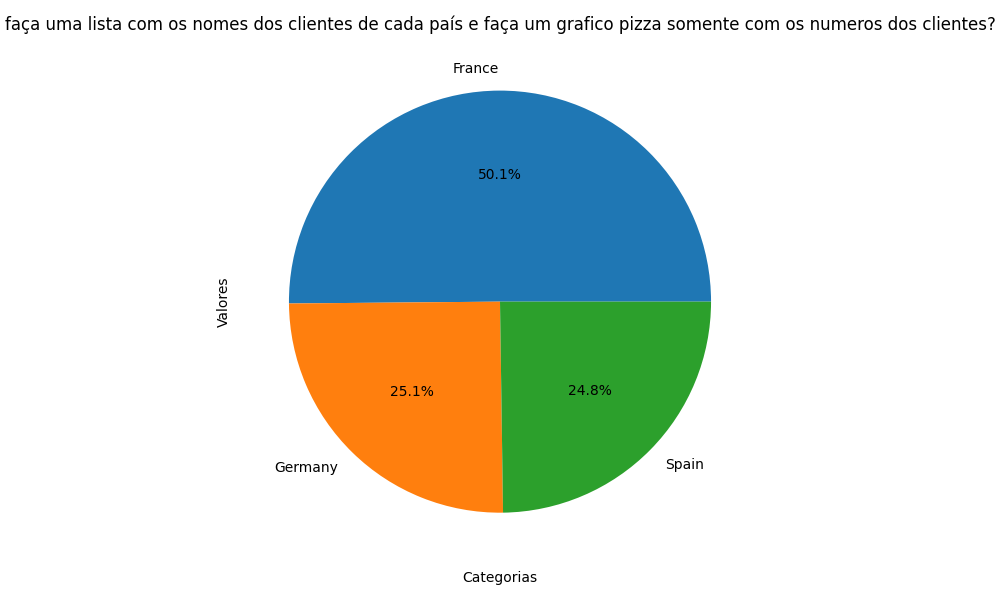

In [16]:
pergunta = "faça uma lista com os nomes dos clientes de cada país e faça um grafico pizza somente com os numeros dos clientes?"
process_question(pergunta)